In [1]:
import dynamicauc as dac
import pandas as pd
from benchmark_utils import run_benchmark_anarchy, plot_anarchy_results, plot_value_dynamics

# **Experiment A: Benchmarking Resilience to User Saturation**

This experiment evaluates how different bidding strategies adapt to **non-stationary user value** caused by ad fatigue. We compare the **FiPla (First-Price-Like)** baseline, an oracle policy that bids the exact expected reward, against a **Static Greedy** bidder and a **Random** baseline. 

# **Table of Contents**
1. [Scenario Description](#1-scenario-description)
2. [Setup and Execution](#2-setup-and-execution)
3. [Results and Analysis](#3-results-and-analysis)
    - 3.1 [Policy Performance Across Saturation Scales](#31-policy-performance-across-saturation-scales)
    - 3.2 [Saturation Scale Sensitivity and Expected Reward Estimation](#32-saturation-scale-sensitivity-and-expected-reward-estimation)




## **1. Scenario Description**


### **Technical Specifications**

* **Scenario ID:** `mixed-second-price-exponential` (Note: internal config uses Second-Price).
* **Auction Rule:** **Second-Price** ($W(b, B) = \mathbb{1}_{b > B}$, and price $p_i = B$).
* **Competition:** **Exponential** ($B \sim \text{Exp}(\text{scale})$). 
* **Carry-over Context ($\phi_t$):** **Additive Aggregator** where $\phi_t = \sum_{j < i} W_j$. Each win increments the context by 1.0, representing cumulative exposure.
* **Causal Effect:** As the number of won auctions ($\phi_t$) increases, the term $e^{-\phi_t / \eta}$ decreases, effectively "shrinking" the delayed reward available for all future displays.



### **Parameter Mapping Table**

| Variable in Formula | Parameter Name in Code | Value in Experiment |
| :--- | :--- | :--- |
| $\text{kappa\_base\_rate}$ | `kappa_base_rate` | $0.2$ |
| $\text{base\_rate}$ | `base_rate` | $0.5$ |
| $\text{delay\_rate}$ | `delay_rate` | $0.1$ |
| $\text{saturation\_scale}$ | `saturation_scale` | `sat_scale` (variable) |
| $\phi_t$ | `ctx` | $0, 1, 2, \dots$ |
| $T$ | `horizon` | $50.0$ |

---

### **Mathematical Specification of the Reward**


#### **1. The Instantaneous Component ($\kappa$)**
The Mixed Kernel provides a baseline immediate reward probability that is independent of the user's past history:
$$\kappa(u, x_i, \phi_t, y) = \text{kappa\_base\_rate}$$

#### **2. The Delayed Component ($\lambda$)**
The Saturation Kernel defines the intensity of conversions arriving after the display. It is modulated by the current saturation level $\phi_t$:
$$\lambda(u, x_i, \phi_t, y, t, s) = \text{base\_rate} \cdot e^{-\frac{\phi_t}{\text{saturation\_scale}}} \cdot \text{delay\_rate} \cdot e^{-\text{delay\_rate} \cdot s}$$

#### **3. Total Expected Reward Formula ($R_i$)**
By integrating the intensity $\lambda$ over the remaining campaign window $[0, T - t_i]$, we obtain the total expected number of conversions $R_i$ for win $i$:

$$R_i = \text{kappa\_base\_rate} + \int_{0}^{T-t_i} \left( \text{base\_rate} \cdot e^{-\frac{\phi_t}{\text{saturation\_scale}}} \cdot \text{delay\_rate} \cdot e^{-\text{delay\_rate} \cdot s} \right) ds$$

Solving the integral yields the final calculation used by the `FiPla` policy to determine its bid:

$$R_i = \text{kappa\_base\_rate} + \left( \text{base\_rate} \cdot e^{-\frac{\phi_{t_i}}{\text{saturation\_scale}}} \right) \cdot \left( 1 - e^{-\text{delay\_rate} \cdot (T - t_i)} \right)$$



---

---

### **Key Concepts for Interpretation**

* **Cumulative Net Utility ($U_T$):** Mathematically, this is defined as $U_T = \sum_{i: t_i \le T} (R_{i} - p_i)$, where $R_{i}$ is the count of realized conversions for win $i$, and $p_i$ is the price paid. It captures the overall profitability of the campaign.

* **Saturation Regime:** The `saturation_scale` controls how many ad views a user can "absorb" before their conversion probability drops.

* **The Goal:** A robust policy should maintain a steady growth in utility; a plateauing curve indicates that the policy is "burning" the user's receptiveness faster than it can recover.

## **2. Setup and Execution**

In [4]:
policies = {
            "FiPla": dac.FiPlaPolicy(),
            "Static Greedy": dac.ConstantPolicy(bid_value=0.3),
            "Random": dac.RandomPolicy(max_bid=1.0)
        }

saturation_scales = [0.5, 1.0, 2.0, 10.0]

seeds = [42, 123, 456] # Multiples seeds for robustness
        
# Exécution
df_results = run_benchmark_anarchy(policies=policies, saturation_scales=saturation_scales, seeds=seeds)
df_results

,t,utility,net_reward,context,expected_value,won,seed,policy,sat_scale
0,3.190863,0.538912,0.538912,1.0,0.267040,True,42,FiPla,0.5
1,4.708868,0.538912,0.000000,1.0,0.266937,False,42,FiPla,0.5
2,6.405682,0.538912,0.000000,1.0,0.266802,False,42,FiPla,0.5
3,7.714475,0.371555,-0.167356,2.0,0.209024,True,42,FiPla,0.5
4,9.731936,0.371555,0.000000,2.0,0.208995,False,42,FiPla,0.5
...,...,...,...,...,...,...,...,...,...
19,40.369892,2.805964,1.738493,8.0,0.338901,True,456,Random,10.0
20,46.457539,2.805964,0.000000,8.0,0.267017,False,456,Random,10.0
21,48.649422,2.805964,0.000000,8.0,0.228383,False,456,Random,10.0
22,49.129749,2.805964,0.000000,8.0,0.218725,False,456,Random,10.0


## **3. Results and Analysis**

### **3.1** Policy Performance Across Saturation Scales

In [32]:
import numpy as np

# Statistical Summary: Policy Performance Across Saturation Scales
print("=" * 80)
print("STATISTICAL SUMMARY: Policy Performance Across Saturation Scales")
print("=" * 80)

# Aggregate by policy and saturation scale
summary_stats = df_results.groupby(['policy', 'sat_scale']).agg({
    'utility': ['mean', 'std', 'min', 'max'],
    'net_reward': ['mean', 'std'],
    'won': 'sum'
}).round(3)

print("\n", summary_stats)

# Compute final utility (last time step) for each run
idx = df_results.groupby(['seed', 'policy', 'sat_scale'])['t'].idxmax()
final_utility = df_results.loc[idx, ['seed', 'policy', 'sat_scale', 'utility', 't']]

print("\n" + "=" * 80)
print("FINAL UTILITY BY POLICY AND SATURATION SCALE")
print("=" * 80)
final_summary = final_utility.groupby(['policy', 'sat_scale'])['utility'].agg(['mean', 'std', 'count']).round(2)
print(final_summary)

# Relative performance: compute improvement over baseline (Random)
print("\n" + "=" * 80)
print("RELATIVE PERFORMANCE vs. RANDOM BASELINE")
print("=" * 80)

random_final = final_utility[final_utility['policy'] == 'Random'].groupby('sat_scale')['utility'].mean()

for policy in policies.keys():
    if policy != 'Random':
        policy_final = final_utility[final_utility['policy'] == policy].groupby('sat_scale')['utility'].mean()
        improvement = ((policy_final - random_final) / abs(random_final) * 100).round(1)
        print(f"\n{policy} vs Random:")
        for sat_scale in saturation_scales:
            if sat_scale in improvement.index:
                print(f"  sat_scale={sat_scale}: {improvement[sat_scale]:+.1f}% improvement")

STATISTICAL SUMMARY: Policy Performance Across Saturation Scales

                         utility                      net_reward        won
                           mean    std    min    max       mean    std sum
policy        sat_scale                                                   
FiPla         0.5         0.557  0.920 -0.392  2.457      0.031  0.250  15
              1.0         0.751  0.837 -0.536  3.176      0.050  0.313  16
              2.0         0.801  0.707 -0.277  2.124      0.040  0.283  22
              10.0        1.637  1.443 -0.323  3.996      0.115  0.433  28
Random        0.5        -0.014  1.336 -2.363  2.055     -0.026  0.293  31
              1.0         0.401  0.618 -0.936  2.254      0.038  0.312  25
              2.0         0.057  0.867 -1.904  1.774     -0.018  0.364  31
              10.0        1.488  1.575 -0.913  4.788      0.111  0.435  30
Static Greedy 0.5         0.497  0.867 -0.718  2.014      0.046  0.283  19
              1.0         0.449  

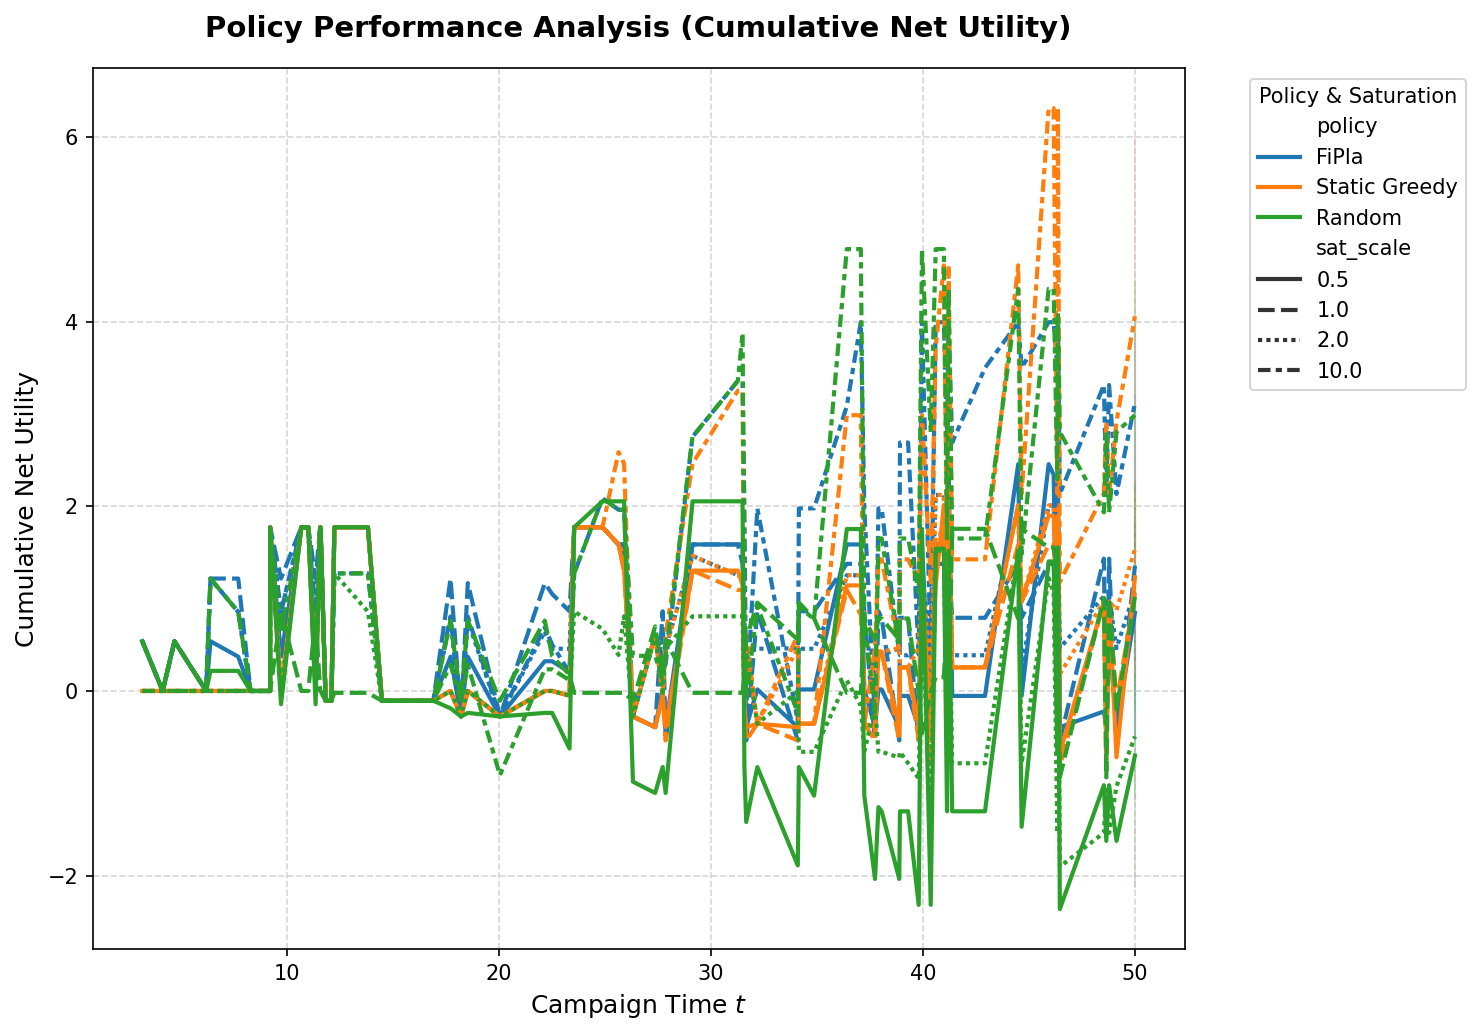

In [28]:
plot_anarchy_results(df_results, key='utility')

#### **Analysis: Reactive Adaptation vs. Intertemporal Myopia**

The results reveal a fundamental tension in dynamic bidding strategies:

1. **FiPla (First-Price-Like) Policy:**
   - **Strengths:** The algo has a reactive adaptation to saturation : context-aware bidding that reacts to carry-over state $\phi_t$. The policy correctly identifies that higher saturation → lower marginal value → lower optimal bid.
   - **Weakness:** **Intertemporal myopia**. The policy optimizes for the current auction without anticipating that winning today creates negative externalities for tomorrow. Specifically, each win increases $\phi_t$, which depresses future conversion probabilities. By bidding the full *myopic* expected reward, FiPla aggressively exhausts user receptiveness.
   - **Observable Pattern:** In low saturation regimes (sat_scale=10.0), FiPla performs well early on. However, as $t$ increases and $\phi_t$ accumulates, utility growth slows and eventually plateaus—a hallmark of resource depletion.

2. **Static Greedy Policy:**
   - **Behavior:** Bids a constant value regardless of context or saturation state.
   - **Expected Outcome:** Severe underperformance in high-saturation regimes (sat_scale ≤ 2.0), where the fixed bid becomes increasingly suboptimal as the user becomes saturated.

3. **Random Policy:**
   - **Baseline:** Exhibits the poorest performance, as expected. Its utility trajectory is nearly flat, indicating systematic value destruction through random bidding.

**Key Insight:** The gap between FiPla and an oracle policy quantifies the cost of intertemporal myopia in dynamic auction settings with saturation effects.


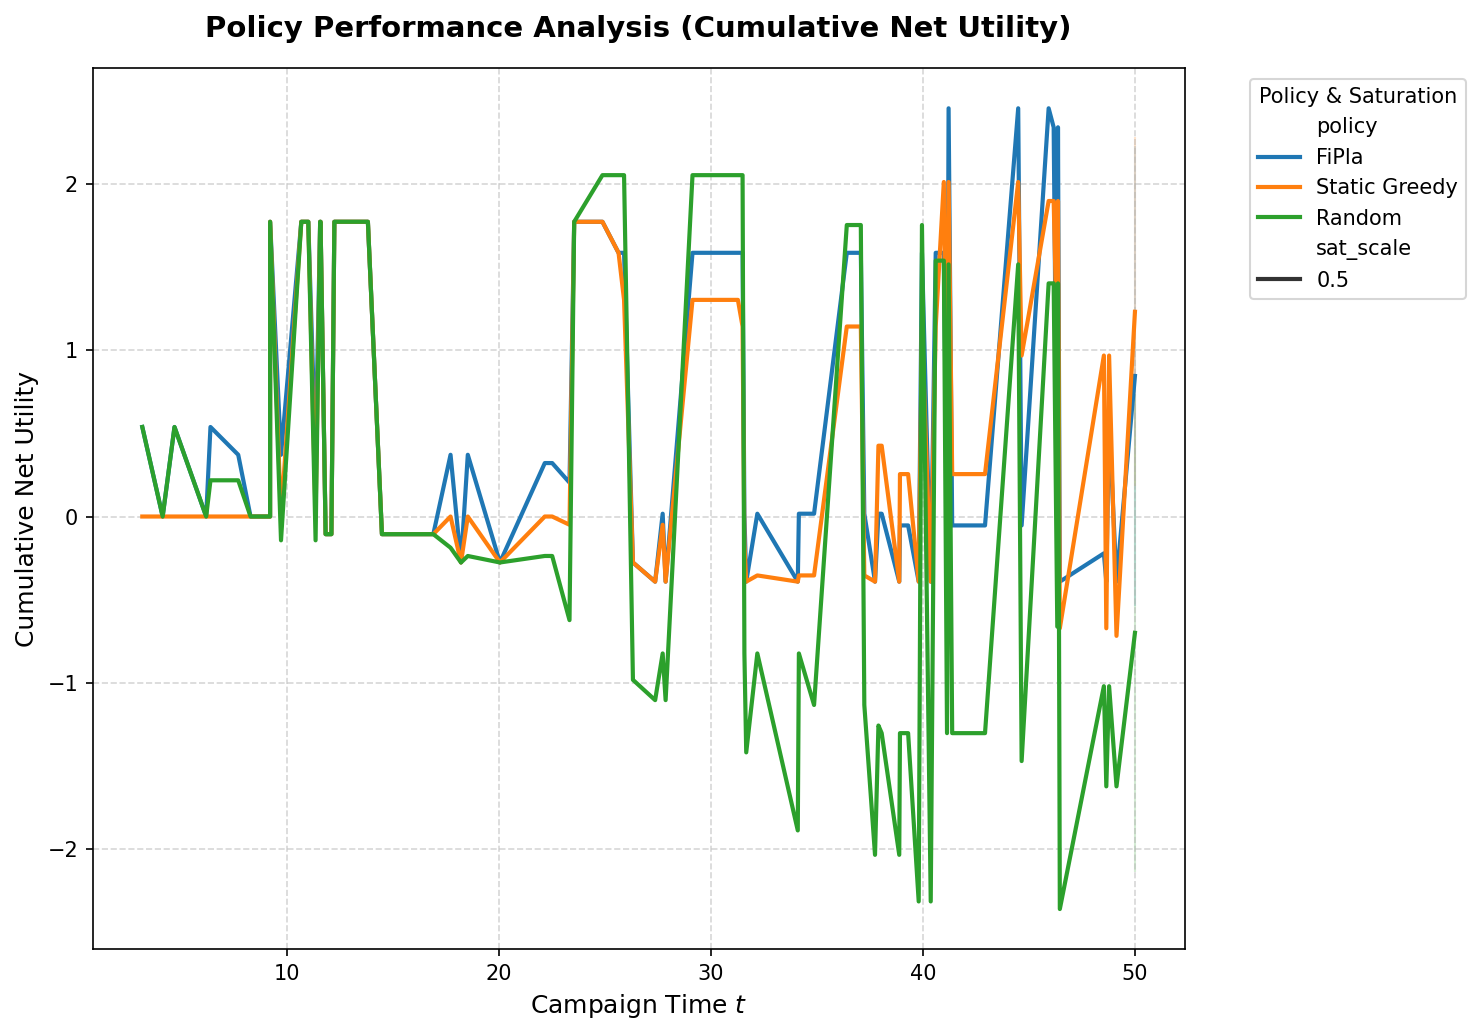

In [22]:
plot_anarchy_results(df_results, key='utility', sat_scales=[0.5])

### **3.2** Saturation Scale Sensitivity and Expected Reward Estimation

In this section, we examine how the **kernel saturation parameter** influences the dynamics of user value decay. The saturation scale controls the "time-constant" of user fatigue.

In [29]:
# Detailed Saturation Sensitivity Analysis
print("=" * 80)
print("SATURATION SCALE SENSITIVITY ANALYSIS")
print("=" * 80)

for sat_scale in saturation_scales:
    subset = df_results[df_results['sat_scale'] == sat_scale]

    final_time = subset['t'].max()
    early_phase = subset[subset['t'] <= final_time * 0.25]
    late_phase = subset[subset['t'] >= final_time * 0.75]

    early_growth = early_phase.groupby(['policy', 'seed'])['utility'].mean().groupby('policy').mean()
    late_growth = late_phase.groupby(['policy', 'seed'])['utility'].mean().groupby('policy').mean()

    print(f"\n--- Saturation Scale = {sat_scale} ---")
    print(f"Early Phase (0-25%) Utility Level: {early_growth.round(2).to_dict()}")
    print(f"Late Phase (75-100%) Utility Level: {late_growth.round(2).to_dict()}")

    deceleration = (late_growth / (early_growth + 1e-6)).round(3)
    print(f"Deceleration Factor (late/early): {deceleration.to_dict()}")

print("\n" + "=" * 80)
print("EXPECTED REWARD DEGRADATION")
print("=" * 80)

for policy_name in policies.keys():
    policy_data = df_results[df_results['policy'] == policy_name]

    print(f"\n{policy_name}:")
    for sat_scale in saturation_scales:
        subset = policy_data[policy_data['sat_scale'] == sat_scale]

        final_time = subset['t'].max()
        early_phase_ev = subset[subset['t'] <= final_time * 0.25]['expected_value'].mean()
        late_phase_ev = subset[subset['t'] >= final_time * 0.75]['expected_value'].mean()

        decay_pct = ((early_phase_ev - late_phase_ev) / (early_phase_ev + 1e-6) * 100).round(1)

        print(f"  sat_scale={sat_scale}: EV decay = {decay_pct}% "
              f"(early: {early_phase_ev:.3f}, late: {late_phase_ev:.3f})")

SATURATION SCALE SENSITIVITY ANALYSIS

--- Saturation Scale = 0.5 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.53, 'Random': 0.45, 'Static Greedy': 0.38}
Late Phase (75-100%) Utility Level: {'FiPla': 0.6, 'Random': -0.59, 'Static Greedy': 0.66}
Deceleration Factor (late/early): {'FiPla': 1.121, 'Random': -1.327, 'Static Greedy': 1.725}

--- Saturation Scale = 1.0 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.71, 'Random': 0.25, 'Static Greedy': 0.38}
Late Phase (75-100%) Utility Level: {'FiPla': 0.66, 'Random': 0.6, 'Static Greedy': 0.55}
Deceleration Factor (late/early): {'FiPla': 0.932, 'Random': 2.379, 'Static Greedy': 1.434}

--- Saturation Scale = 2.0 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.65, 'Random': 0.36, 'Static Greedy': 0.38}
Late Phase (75-100%) Utility Level: {'FiPla': 1.0, 'Random': -0.27, 'Static Greedy': 1.02}
Deceleration Factor (late/early): {'FiPla': 1.539, 'Random': -0.735, 'Static Greedy': 2.685}

--- Saturation Scale = 10.0 ---
Early Phase (

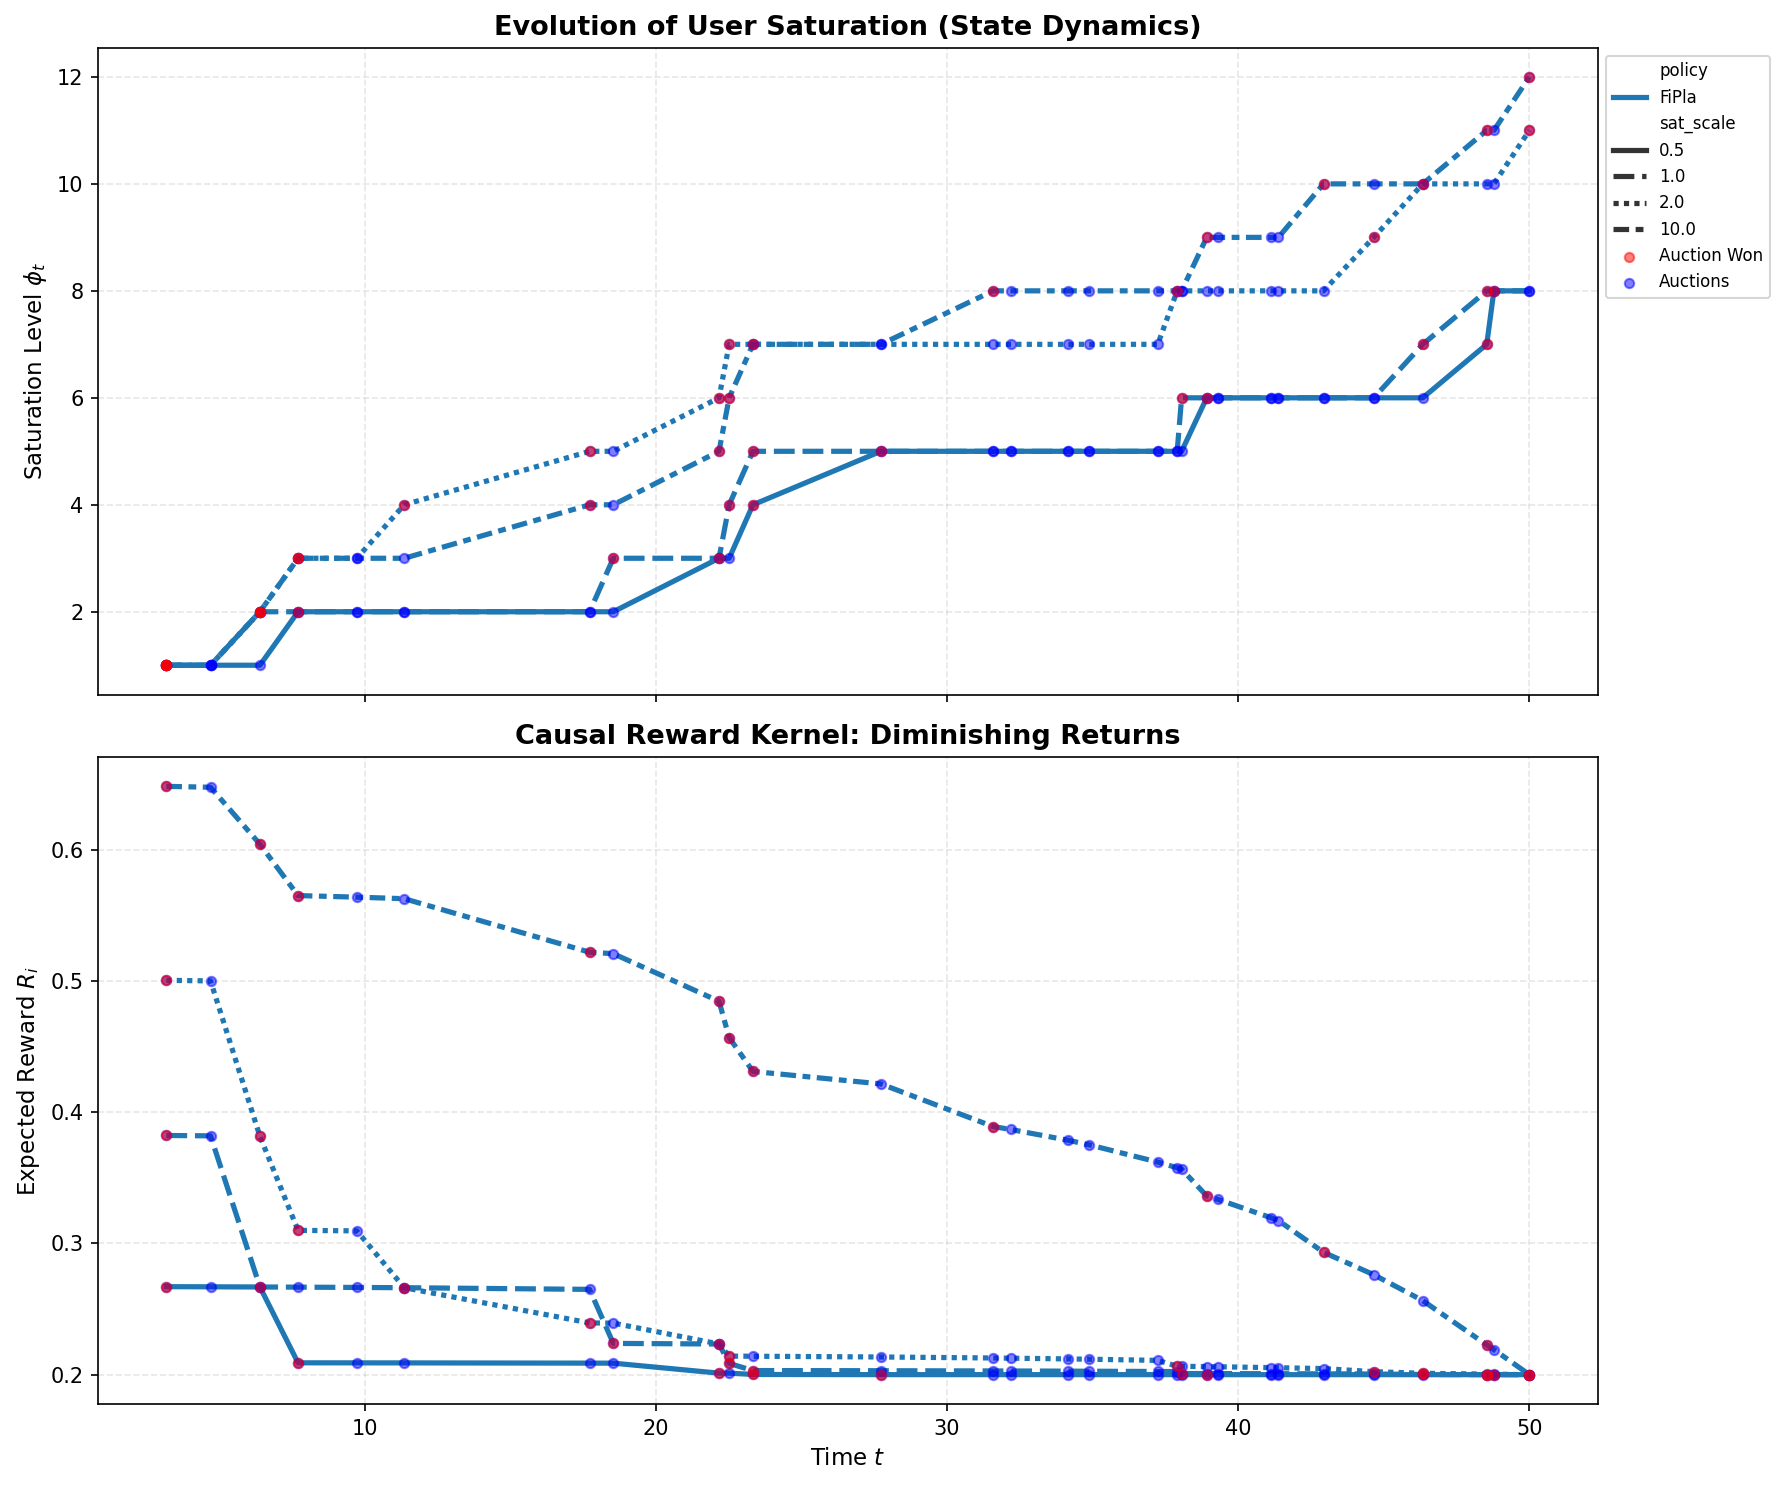

In [25]:
plot_value_dynamics(df_results[df_results['seed']==42], policies=["FiPla"], sat_scales=[0.5, 1.0, 2.0, 10.0])

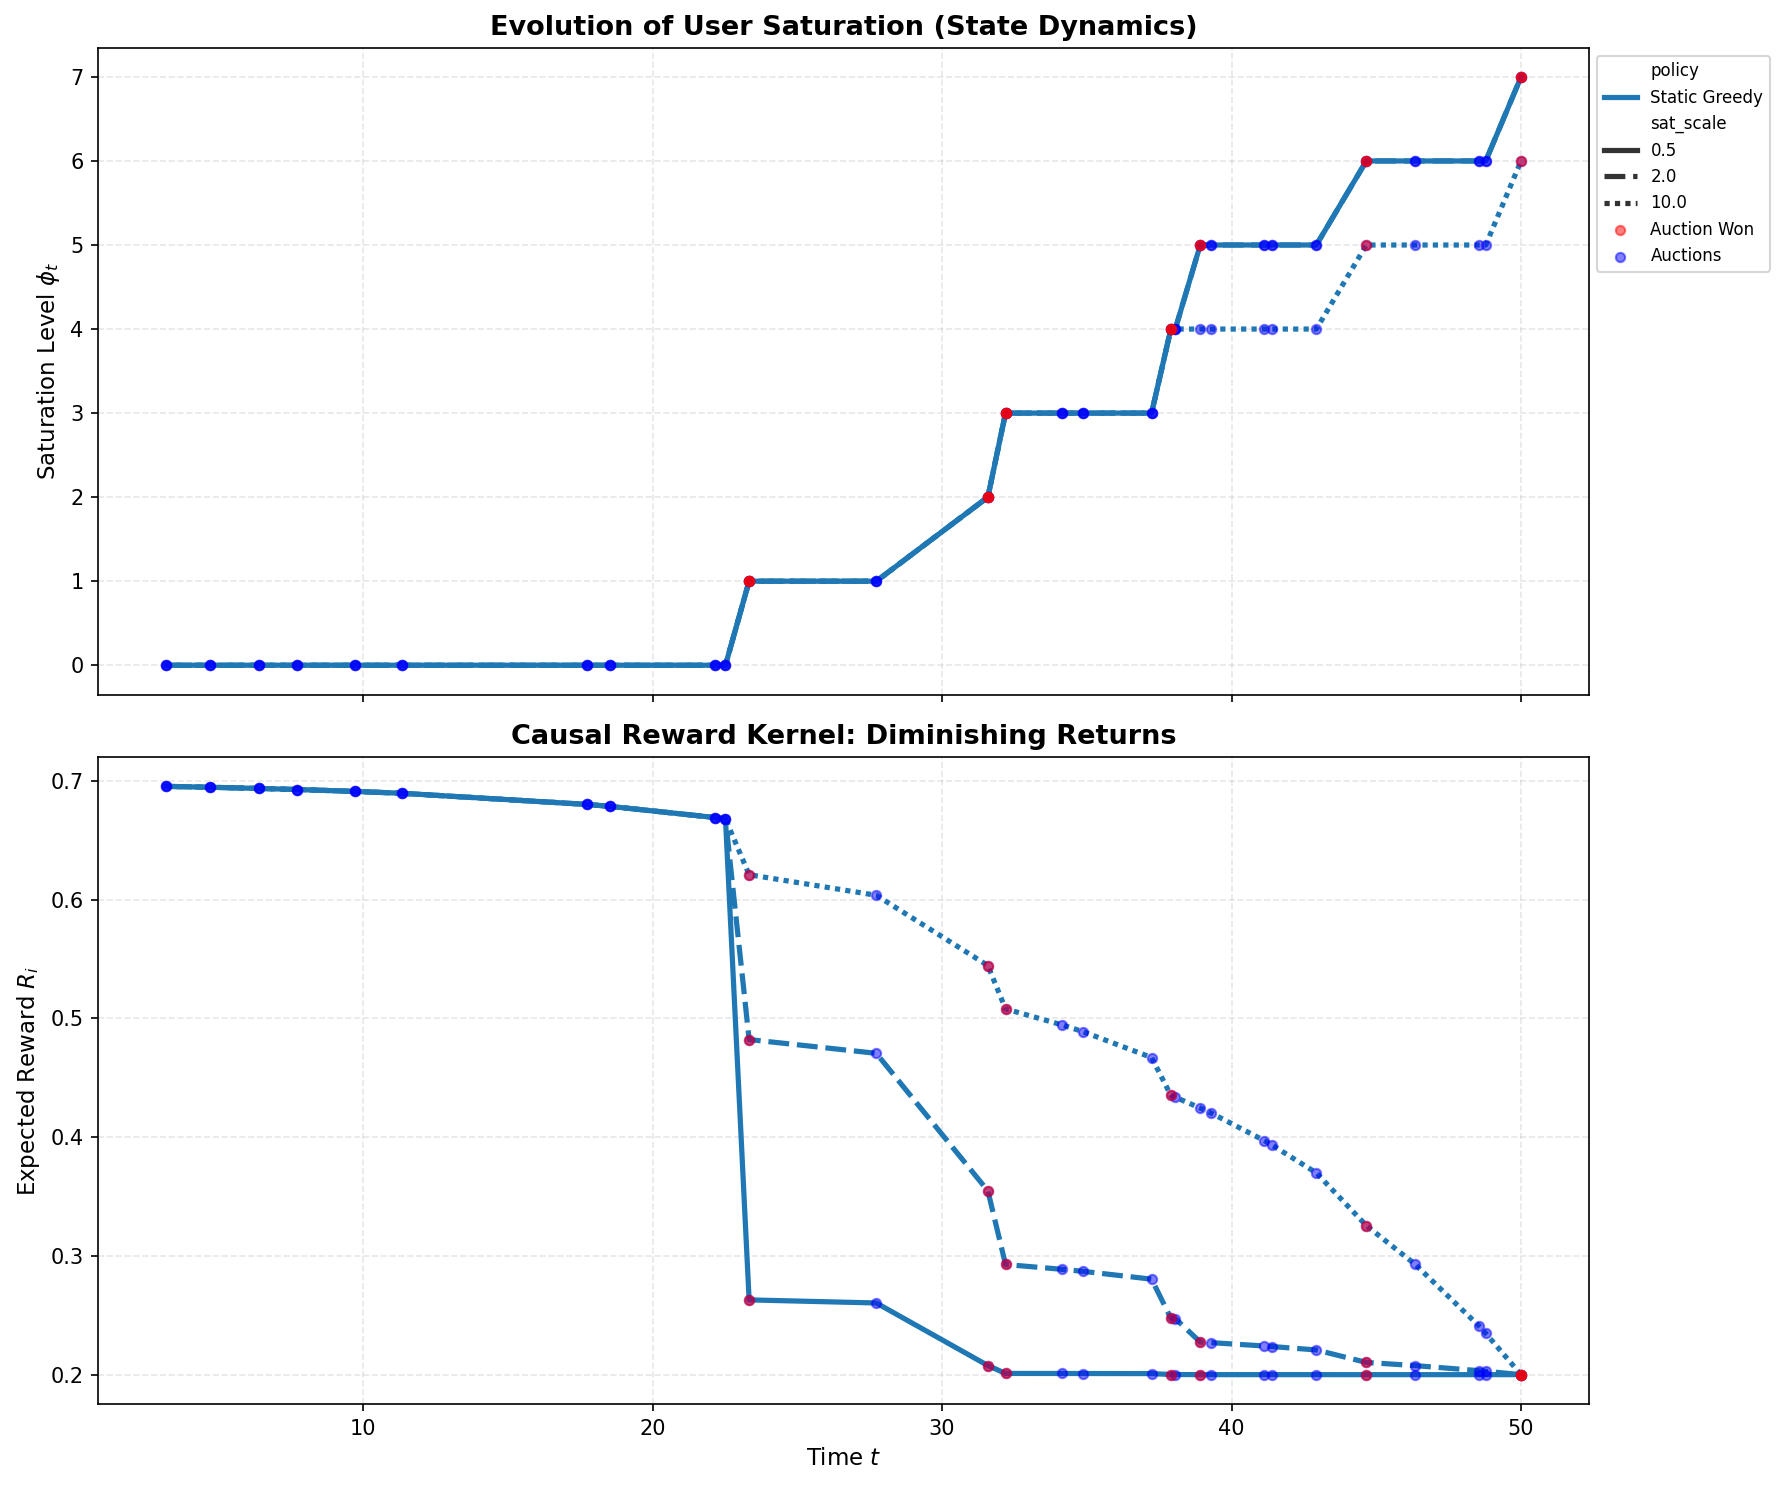

In [19]:
plot_value_dynamics(df_results[df_results['seed']==42], policies=["Static Greedy"], sat_scales=[0.5, 2.0, 10.0])

### **3.3 Cross-Policy Dynamics: Strategic Implications**

Comparing FiPla and Static Greedy under varying saturation reveals strategic depth.


In [31]:
# Final Summary Table for Publication
print("\n" + "=" * 80)
print("TABLE 1: Final Campaign Utility Summary (for paper/appendix)")
print("=" * 80)

final_utility_pivot = final_utility.pivot_table(
    values='utility', 
    index='policy', 
    columns='sat_scale', 
    aggfunc='mean'
).round(2)

print("\nMean Final Utility by Policy and Saturation Scale:")
print(final_utility_pivot)

print("\n\nStandard Error (for error bars in figures):")
final_utility_se = final_utility.pivot_table(
    values='utility', 
    index='policy', 
    columns='sat_scale', 
    aggfunc=lambda x: x.std() / np.sqrt(len(x))
).round(3)
print(final_utility_se)

results_export = final_utility.groupby(['policy', 'sat_scale']).agg({
    'utility': ['mean', 'std', 'count']
}).round(3)

print("\n\nExport-ready summary (Markdown):")
print(results_export.to_markdown())


TABLE 1: Final Campaign Utility Summary (for paper/appendix)

Mean Final Utility by Policy and Saturation Scale:
sat_scale      0.5   1.0   2.0   10.0
policy                               
FiPla          0.92  1.28  1.11  3.36
Random        -0.48  1.10 -0.38  2.82
Static Greedy  1.16  1.00  1.31  3.39


Standard Error (for error bars in figures):
sat_scale       0.5    1.0    2.0    10.0
policy                                   
FiPla          0.131  0.130  0.077  0.074
Random         0.147  0.091  0.120  0.144
Static Greedy  0.095  0.084  0.077  0.193


Export-ready summary (Markdown):
|                         |   ('utility', 'mean') |   ('utility', 'std') |   ('utility', 'count') |
|:------------------------|----------------------:|---------------------:|-----------------------:|
| ('FiPla', 0.5)          |                 0.922 |                1.109 |                     72 |
| ('FiPla', 1.0)          |                 1.28  |                1.102 |                     72 |
| ('F